# Detección de fraude: distancia de Mahalanobis vs. kernel de Christoffel-Darboux

**La idea en una frase:** aprendemos cómo se ve una transacción *legítima* y marcamos como sospechosa cualquier transacción que se aleje mucho de ese patrón.

Los dos métodos siguen la **misma receta**. Lo único que cambia es la fórmula del paso 1:

| Paso | Qué hacemos |
|---|---|
| 1. **Puntaje de rareza** | A cada transacción le asignamos un número: pequeño = se parece a las legítimas; grande = es rara. Mahalanobis usa $d_M(x)$ y el kernel CD usa $p_{CD}(x)$. |
| 2. **Umbral ρ** | Elegimos un umbral que deja "dentro" a cierto porcentaje de las legítimas de entrenamiento (ρ₉₅ deja dentro al 95 %). |
| 3. **Decisión** | Si el puntaje de una transacción es mayor que ρ, la marcamos como **fraude**. |
| 4. **Validación** | Aplicamos la regla a `X_test_pca` y contamos aciertos y errores. |

**Contenido**
1. Preparación de los datos
2. Primera propuesta: distancia de Mahalanobis
3. Segunda propuesta: kernel de Christoffel-Darboux
4. Comparación final (tabla y gráfica del reporte)
5. Resumen para la presentación

## Librerías

In [206]:
import time
from itertools import combinations_with_replacement
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 1. Preparación de los datos

### 1.1 y 1.2 Cargar las transacciones de México

El filtrado por país (`merchant_country`) y la selección de las columnas numéricas se hicieron en `data_ingestion.ipynb`, que guardó el resultado en `data/preprocessed/mexico_fraud_num.csv`. Aquí solo lo cargamos.

Quitamos `fraud_amount_lost` porque **delata la respuesta**: vale 0 en todas las legítimas y es mayor que 0 en todos los fraudes (la celda lo muestra). Si el modelo la viera, estaría haciendo trampa; a esto se le llama *fuga de información*.

In [207]:
mexico_fraud_num = pd.read_csv("../data/preprocessed/mexico_fraud_num.csv")

# Mínimo y máximo de fraud_amount_lost en legítimas (0) y fraudes (1)
print(mexico_fraud_num.groupby("is_fraud")["fraud_amount_lost"].agg(["min", "max"]))

mexico_fraud_num = mexico_fraud_num.drop(columns=["fraud_amount_lost"])
print("\nTransacciones:", len(mexico_fraud_num), "| columnas:", mexico_fraud_num.shape[1])
mexico_fraud_num["is_fraud"].value_counts()

           min      max
is_fraud               
0         0.00     0.00
1         3.64  1781.88

Transacciones: 1921 | columnas: 27


is_fraud
0    1869
1      52
Name: count, dtype: int64

### 1.3 Separar entrenamiento (80 %) y prueba (20 %)

- `X` son las 26 columnas numéricas y `y` es la etiqueta `is_fraud` (1 = fraude, 0 = legítima).
- `X_test` se aparta y **no se usa para aprender nada**: simula transacciones nuevas que el modelo nunca vio.
- `stratify=y` mantiene el mismo porcentaje de fraudes (≈ 2.7 %) en los dos conjuntos. Con solo 52 fraudes, sin esto el test podría quedarse con muy pocos.
- `random_state=42` fija el sorteo para que la división salga igual cada vez que se corre la libreta.

In [208]:
X = mexico_fraud_num.drop(columns=["is_fraud"])   # 26 columnas numéricas
y = mexico_fraud_num["is_fraud"]                  # 1 = fraude, 0 = legítima

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train: {len(X_train)} transacciones, {y_train.sum()} fraudes")
print(f"X_test:  {len(X_test)} transacciones, {y_test.sum()} fraudes")

X_train: 1536 transacciones, 42 fraudes
X_test:  385 transacciones, 10 fraudes


### 1.4 Estandarizar y aplicar PCA a `X_train`


In [209]:
# Desviación estándar de cada columna ANTES de estandarizar
print(X_train.std().sort_values(ascending=False).round(2).to_string())

credit_limit                   6520.36
distance_from_home_km          4221.58
distance_from_last_tx_km       2628.50
account_age_days                761.78
amount_last_24h                 581.08
transaction_amount              342.69
amount_last_1h                  264.77
avg_transaction_amount_30d      128.11
credit_score                     92.91
std_transaction_amount_30d       77.59
customer_age                     14.78
amount_vs_avg_ratio               6.22
transactions_last_7d              6.20
transaction_hour                  4.93
days_since_last_transaction       3.23
transactions_last_24h             2.45
transactions_last_1h              1.40
num_cards_held                    1.17
num_declined_last_30d             0.96
num_chargebacks_ever              0.72
card_present                      0.48
used_chip                         0.46
is_weekend                        0.46
used_pin                          0.39
international_transaction         0.00
high_risk_country        

In [210]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   

pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(X_train_scaled) 

print("X_train_scaled:", X_train_scaled.shape, "→ X_train_pca:", X_train_pca.shape)

X_train_scaled: (1536, 26) → X_train_pca: (1536, 10)


La nueva codificación de `X_train` (10 componentes): 

In [211]:
train_pca = pd.DataFrame(X_train_pca, columns=nombres_pc, index=X_train.index)
train_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
1783,-0.704838,-0.909824,-1.466560,-0.347346,0.120313,1.846079,-1.106053,-0.717050,-0.511488,-0.266149
337,-1.021251,1.710889,0.211601,-0.141214,-0.196984,-0.115011,0.126335,0.747761,0.356117,-0.070398
614,1.664014,-1.160899,-2.436604,0.605898,0.709812,0.168727,1.301692,0.298973,1.345257,0.722493
299,0.096168,-1.207897,1.380113,3.257464,-1.760844,-0.027560,-1.494220,0.384377,-0.120384,-0.764895
445,0.275278,-1.191474,-1.690585,0.038305,0.112962,0.007757,-1.377057,-0.971714,0.679402,-1.101606


**PCA en términos de la SVD.** Si escribimos $X_{scaled} = U \Sigma V^T$:

- Los renglones de $V^T$ (columnas de $V$) son las **direcciones principales**, ordenadas de mayor a menor valor singular. Nos quedamos con las 10 primeras: $V_{10}$, una matriz de 26 × 10.
- Las nuevas coordenadas son $X_{pca} = X_{scaled}\, V_{10} = U_{10}\,\Sigma_{10}$.
- La varianza de la componente $i$ es $\sigma_i^2 / (n - 1)$.

La celda siguiente comprueba numéricamente que el `PCA` de sklearn calcula exactamente esto.

In [212]:
U, S, Vt = np.linalg.svd(X_train_scaled, full_matrices=False)
V10 = Vt[:10].T   # 26 × 10

# Los signos de los vectores singulares son arbitrarios (v y −v sirven igual), por eso se comparan valores absolutos
print("pca.components_ = primeros 10 renglones de Vᵀ:", np.allclose(np.abs(pca.components_), np.abs(Vt[:10])))
print("X_train_pca = X_train_scaled · V₁₀:          ", np.allclose(np.abs(X_train_pca), np.abs(X_train_scaled @ V10)))
print("varianza de cada componente = σᵢ² / (n − 1):  ", np.allclose(pca.explained_variance_, S[:10] ** 2 / (len(X_train_scaled) - 1)))

pca.components_ = primeros 10 renglones de Vᵀ: True
X_train_pca = X_train_scaled · V₁₀:           True
varianza de cada componente = σᵢ² / (n − 1):   True


### 1.5 Preparar el conjunto de prueba: `X_test_pca`

A `X_test` **solo** se le aplica `transform`, nunca `fit`: se reutilizan la media μ, la desviación σ y las direcciones $V_{10}$ que se aprendieron con `X_train`. Matemáticamente:

$$X_{test\_pca} = \left(\frac{X_{test} - \mu_{train}}{\sigma_{train}}\right) V_{10}$$

Es decir, proyectamos las transacciones nuevas sobre los mismos 10 ejes del entrenamiento. Si hiciéramos `fit` con el test, usaríamos información de transacciones que en la vida real todavía no han llegado.

In [213]:
X_test_scaled = scaler.transform(X_test)   # usa μ y σ de X_train
X_test_pca = pca.transform(X_test_scaled)  # usa las direcciones V₁₀ de X_train

## 2. Primera propuesta: distancia de Mahalanobis

### 2.1 Separar legítimas y fraudes de entrenamiento

Los dos métodos **aprenden solo con las legítimas** (`X_train_legit`). Los fraudes de entrenamiento (`X_train_fraude`) solo se usan para definir las zonas de seguridad, y `y_real` (las etiquetas del test) solo para validar.

In [214]:
es_legitima = (y_train == 0).to_numpy()
X_train_legit = X_train_pca[es_legitima] # Filtra las transacciones legítimas
X_train_fraude = X_train_pca[~es_legitima]
y_real = y_test.to_numpy()

print("X_train_legit: ", X_train_legit.shape)
print("X_train_fraude:", X_train_fraude.shape)

X_train_legit:  (1494, 10)
X_train_fraude: (42, 10)


### 2.2 La fórmula

$$d_M(x)^2 = x^T \Sigma^{-1} x$$

donde Σ es la matriz de covarianzas de `X_train_legit`.

**Intuición:** es una distancia al origen que toma en cuenta cómo se dispersan los datos. En una dirección donde las legítimas varían mucho, alejarse no es raro; en una dirección donde varían poco, alejarse un poco ya es sospechoso. Por eso los puntos con la misma distancia de Mahalanobis forman una **elipse**, no un círculo. Medimos desde el origen porque, después de estandarizar y aplicar PCA, los datos están centrados en 0.

La distancia se calcula en el espacio de las **k componentes** que usemos (2 o 10), no en las 26 columnas originales.

**Dos funciones que se usan en toda la libreta:**

- `forma_cuadratica(Z, A)` calcula el número $z^T A z$ para cada renglón $z$. Mahalanobis la usa con $z = x$ y $A = \Sigma^{-1}$. Más adelante el kernel CD la usa con $z = \Phi(x)$ y $A = M^{-1}$: **es la misma operación en los dos métodos.**
- `radio(puntajes, n)` encuentra ρₙ: ordena los puntajes de menor a mayor y toma el primero que deja dentro al menos el n %. Ejemplo: con 1,494 legítimas y n = 95, se necesitan ⌈0.95 · 1494⌉ = 1,420 puntos, así que ρ₉₅ es el puntaje número 1,420 de la lista ordenada. Dentro queda el 1420/1494 = 95.05 %: al menos el 95 %, pero no el 96 %.

In [215]:
def forma_cuadratica(Z, A):
    """Para cada renglón z de Z calcula el número zᵀ A z."""
    return np.array([z @ A @ z for z in Z])


def radio(puntajes, n):
    """ρₙ: el puntaje que deja dentro el n % de los datos, pero no el (n+1) %."""
    ordenados = np.sort(puntajes)                       # de menor a mayor
    k = int(np.ceil(n * len(ordenados) / 100))          # cuántos puntos se necesitan para cubrir el n %
    return ordenados[k - 1]                             # el k-ésimo (Python cuenta desde 0)

### 2.3 El método completo

`correr_mahalanobis(k)` hace todo con las primeras k componentes y mide cuánto tarda:

1. **Entrenar:** calcula Σ de las legítimas y su inversa Σ⁻¹.
2. **Calcular puntajes:** $d_M$ de las legítimas y de los fraudes de entrenamiento, y de todo `X_test_pca`.

Guarda todo en un diccionario (`resultado`) para usarlo después en las tablas y gráficas.

In [216]:
def ajustar_mahalanobis(X_legit):
    """Σ⁻¹: inversa de la matriz de covarianzas de las legítimas."""
    sigma = np.cov(X_legit, rowvar=False)   # rowvar=False: cada columna es una variable
    return np.linalg.inv(sigma)


def puntaje_mahalanobis(X, sigma_inv):
    """d_M(x) = √(xᵀ Σ⁻¹ x) para cada transacción x (renglón de X)."""
    return np.sqrt(forma_cuadratica(X, sigma_inv))


def correr_mahalanobis(k):
    """Entrena con las primeras k componentes y calcula los puntajes de entrenamiento y de prueba."""
    inicio = time.perf_counter()   # cronómetro

    sigma_inv = ajustar_mahalanobis(X_train_legit[:, :k])
    resultado = {
        "k": k,
        "sigma_inv": sigma_inv,
        "legit": puntaje_mahalanobis(X_train_legit[:, :k], sigma_inv),
        "fraude": puntaje_mahalanobis(X_train_fraude[:, :k], sigma_inv),
        "test": puntaje_mahalanobis(X_test_pca[:, :k], sigma_inv),
    }

    resultado["segundos"] = time.perf_counter() - inicio
    return resultado

### 2.4 Herramientas de evaluación (sirven para los dos métodos)

Las tablas solo necesitan los **puntajes**, así que funcionan igual para Mahalanobis y para el kernel CD.

**`tabla_radios`**: para ρ₅₀, ρ₇₅, ρ₉₀, ρ₉₅ y ρ₉₉, qué porcentaje de legítimas y de fraudes de entrenamiento queda dentro. *Si el método funcionara, dentro quedarían muchas legítimas y pocos fraudes.*

**`tabla_zonas`**: usa los **fraudes** de entrenamiento para definir cuatro zonas. r₁₀, r₂₅ y r₅₀ son los radios que contienen el 10 %, 25 % y 50 % de los fraudes (la misma función `radio`, aplicada a los fraudes). Los cortes 10 / 25 / 50 son una decisión de diseño.

| Zona | Puntaje | Interpretación |
|---|---|---|
| Seguridad extrema | ≤ r₁₀ | solo el 10 % de los fraudes está así de cerca del centro |
| Seguridad alta | entre r₁₀ y r₂₅ | aquí cae otro 15 % de los fraudes |
| Seguridad baja | entre r₂₅ y r₅₀ | aquí cae otro 25 % de los fraudes |
| Peligro | > r₅₀ | aquí está la mitad más lejana de los fraudes |

Después cuenta cuántas transacciones de `X_test_pca` caen en cada zona. *Si el método funcionara, la zona Peligro tendría un porcentaje de fraude mucho mayor que las demás.*

**`tabla_confusion`**: aplica la regla "fraude si el puntaje es mayor que ρₙ" a `X_test_pca` y cuenta:

| Sigla | En realidad era | El método dijo | |
|---|---|---|---|
| **VN** (verdadero negativo) | legítima | legítima | ✓ |
| **FP** (falso positivo) | legítima | fraude | ✗ falsa alarma |
| **FN** (falso negativo) | fraude | legítima | ✗ fraude que se escapó |
| **VP** (verdadero positivo) | fraude | fraude | ✓ fraude detectado |

In [217]:
PORCENTAJES = [50, 75, 90, 95, 99]
ZONAS = ["Seguridad extrema", "Seguridad alta", "Seguridad baja", "Peligro"]


def calcular_radios(puntajes_legit):
    """[ρ50, ρ75, ρ90, ρ95, ρ99] a partir de los puntajes de las legítimas de entrenamiento."""
    return [radio(puntajes_legit, n) for n in PORCENTAJES]


def tabla_radios(resultado):
    """% de legítimas y de fraudes de entrenamiento dentro de cada radio ρₙ."""
    filas = []
    for n, rho in zip(PORCENTAJES, calcular_radios(resultado["legit"])):
        filas.append({
            "radio": f"ρ{n}",
            "valor": rho,
            "% legítimas dentro": 100 * np.mean(resultado["legit"] <= rho),
            "% fraudes dentro": 100 * np.mean(resultado["fraude"] <= rho),
        })
    return pd.DataFrame(filas).set_index("radio").round(2)


def zona(puntaje, r10, r25, r50):
    """Zona de seguridad de una transacción según su puntaje."""
    if puntaje <= r10:
        return "Seguridad extrema"
    elif puntaje <= r25:
        return "Seguridad alta"
    elif puntaje <= r50:
        return "Seguridad baja"
    else:
        return "Peligro"


def tabla_zonas(resultado):
    """Legítimas y fraudes de X_test_pca en cada zona (radios definidos con los fraudes de entrenamiento)."""
    r10 = radio(resultado["fraude"], 10)
    r25 = radio(resultado["fraude"], 25)
    r50 = radio(resultado["fraude"], 50)
    zonas_test = np.array([zona(p, r10, r25, r50) for p in resultado["test"]])

    filas = []
    for nombre, hasta in zip(ZONAS, [r10, r25, r50, np.inf]):
        en_zona = zonas_test == nombre
        legitimas = np.sum(en_zona & (y_real == 0))
        fraudes = np.sum(en_zona & (y_real == 1))
        filas.append({
            "zona": nombre,
            "puntaje hasta": hasta,
            "legítimas": legitimas,
            "fraudes": fraudes,
            "% fraude en la zona": 100 * fraudes / (legitimas + fraudes),
        })
    return pd.DataFrame(filas).set_index("zona").round(2)


def matriz_confusion(resultado, n=95):
    """VN, FP, FN, VP en X_test_pca con la regla: fraude si el puntaje > ρₙ."""
    rho = radio(resultado["legit"], n)
    dice_fraude = resultado["test"] > rho
    es_fraude = y_real == 1

    vn = np.sum(~dice_fraude & ~es_fraude)   # legítima y la dejamos pasar       ✓
    fp = np.sum(dice_fraude & ~es_fraude)    # legítima marcada como fraude      ✗ falsa alarma
    fn = np.sum(~dice_fraude & es_fraude)    # fraude que no detectamos          ✗
    vp = np.sum(dice_fraude & es_fraude)     # fraude detectado                  ✓
    return vn, fp, fn, vp


def tabla_confusion(resultado):
    """Matriz de confusión en un renglón para cada umbral ρₙ."""
    filas = []
    for n in PORCENTAJES:
        vn, fp, fn, vp = matriz_confusion(resultado, n)
        filas.append({"umbral": f"ρ{n}", "VN": vn, "FP": fp, "FN": fn, "VP": vp})
    return pd.DataFrame(filas).set_index("umbral")

### 2.5 Gráficas en 2D

`graficar_regiones` dibuja las transacciones de entrenamiento y las curvas donde el puntaje vale exactamente ρ₅₀, …, ρ₉₉. Para encontrar esas curvas se calcula el puntaje en una **malla** de 300 × 300 puntos del plano, y `contour` une los puntos que tienen el mismo valor (como las curvas de nivel de un mapa topográfico). Sirve para los dos métodos: solo cambia la función con la que se calcula el puntaje de la malla.

In [218]:
# Estilo de las gráficas (solo apariencia)
plt.rcParams.update({
    "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlelocation": "left", "legend.frameon": False,
})
COLOR_LEGIT = "#898781"                                                 # gris: contexto
COLOR_FRAUDE = "#eb6834"                                                # naranja: fraudes
COLORES_RADIOS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # azul claro (ρ50) → oscuro (ρ99)

# Malla de puntos (x1, x2) que cubre la gráfica
x1 = np.linspace(-7, 12.5, 300)
x2 = np.linspace(-6, 6, 300)
malla_x1, malla_x2 = np.meshgrid(x1, x2)
puntos_malla = np.column_stack([malla_x1.ravel(), malla_x2.ravel()])   # 90,000 renglones (x1, x2)


def graficar_regiones(ax, puntaje_malla, radios, titulo):
    """Transacciones de entrenamiento + curvas de nivel {puntaje = ρₙ} (2 componentes)."""
    ax.scatter(X_train_legit[:, 0], X_train_legit[:, 1], s=8, color=COLOR_LEGIT, alpha=0.35, linewidths=0,
               label="Legítimas (entrenamiento)")
    ax.scatter(X_train_fraude[:, 0], X_train_fraude[:, 1], s=30, color=COLOR_FRAUDE, edgecolors="white",
               linewidths=0.8, zorder=3, label="Fraudes (entrenamiento)")
    ax.contour(malla_x1, malla_x2, puntaje_malla.reshape(malla_x1.shape), levels=radios,
               colors=COLORES_RADIOS, linewidths=1.5)

    # contour no agrega entradas a la leyenda; estas líneas vacías solo sirven para eso
    for n, color in zip(PORCENTAJES, COLORES_RADIOS):
        ax.plot([], [], color=color, linewidth=1.5, label=f"ρ{n} ({n} % de las legítimas)")

    ax.set(title=titulo, xlabel="PC1", ylabel="PC2", xlim=(x1[0], x1[-1]), ylim=(x2[0], x2[-1]))
    ax.set_aspect("equal")   # misma escala en los dos ejes: las formas se ven como son

### 2.6 Ejercicio con 2 componentes

Primero calculamos Σ y comprobamos que la función `radio` cumple lo que pide el enunciado para **todos** los porcentajes enteros: la bola $B_{\rho_n}(0)$ contiene el n % de las legítimas, pero no el (n+1) %.

In [219]:
maha_2 = correr_mahalanobis(2)

print("Σ (covarianzas de las legítimas, 2 componentes):")
print(np.cov(X_train_legit[:, :2], rowvar=False).round(3))

for n in range(1, 100):
    porcentaje_dentro = 100 * np.mean(maha_2["legit"] <= radio(maha_2["legit"], n))
    assert n <= porcentaje_dentro < n + 1
print("\n✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %")

tabla_radios(maha_2)

Σ (covarianzas de las legítimas, 2 componentes):
[[3.281 0.005]
 [0.005 2.066]]

✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %


,valor,% legítimas dentro,% fraudes dentro
radio,,,
ρ50,1.02,50.00,45.24
ρ75,1.38,75.03,88.10
ρ90,1.92,90.03,95.24
ρ95,2.18,95.05,100.00
ρ99,3.64,99.06,100.00


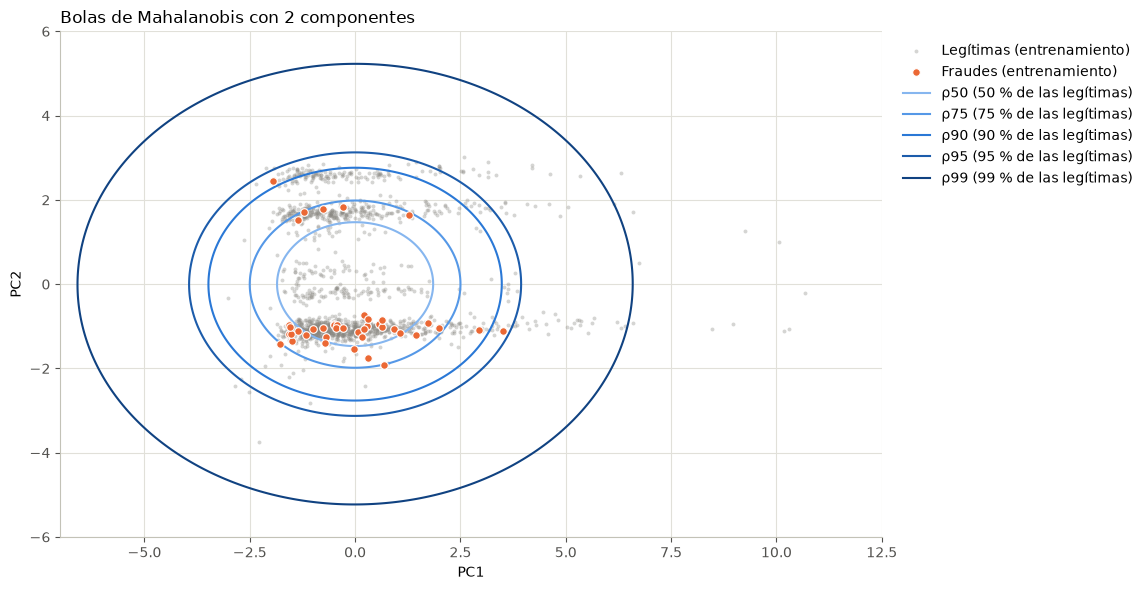

In [220]:
fig, ax = plt.subplots(figsize=(11, 6))
graficar_regiones(ax, puntaje_mahalanobis(puntos_malla, maha_2["sigma_inv"]), calcular_radios(maha_2["legit"]),
                  "Bolas de Mahalanobis con 2 componentes")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Cómo leer la gráfica:** gris = legítimas, naranja = fraudes, y las elipses van de azul claro (ρ₅₀) a azul oscuro (ρ₉₉). Tres legítimas con PC1 > 12.5 quedan fuera de la vista.

- Las legítimas **no** forman una nube con forma de elipse: se acomodan en varias franjas horizontales y tienen una cola que se estira hacia la derecha. Una elipse no puede seguir esa forma.
- Los fraudes están **dentro** de las elipses, en las zonas donde hay más legítimas: todos los fraudes de entrenamiento quedan dentro de ρ₉₅ (columna "% fraudes dentro" de la tabla anterior). Por eso Mahalanobis casi no los detecta.

In [221]:
display(tabla_zonas(maha_2))
tabla_confusion(maha_2)

,puntaje hasta,legítimas,fraudes,% fraude en la zona
zona,,,,
Seguridad extrema,0.71,36,1,2.70
Seguridad alta,0.76,24,0,0.00
Seguridad baja,1.06,125,5,3.85
Peligro,inf,190,4,2.06


,VN,FP,FN,VP
umbral,,,,
ρ50,174,201,6,4
ρ75,287,88,8,2
ρ90,346,29,10,0
ρ95,358,17,10,0
ρ99,371,4,10,0


**Cómo leer estas tablas:** el test tiene 10 fraudes entre 385 transacciones (2.6 %).

- **Zonas:** si funcionaran, la zona Peligro tendría un porcentaje de fraude mucho mayor que las demás. Aquí todas andan entre 0 % y 4 %, así que las zonas no distinguen el fraude.
- **Matriz de confusión:** con ρ₉₅ el método no detecta ninguno de los 10 fraudes (VP = 0) y da 17 falsas alarmas. Si bajamos el umbral a ρ₅₀, atrapa 4 fraudes, pero a cambio acusa a 201 legítimas. Mover el umbral solo cambia un error por otro.

### 2.7 Con las 10 componentes

Es la misma función con k = 10. Ahora las "bolas" son elipsoides en 10 dimensiones, así que ya no se pueden graficar, pero las tablas se calculan igual.

In [222]:
maha_10 = correr_mahalanobis(10)
tabla_radios(maha_10)

,valor,% legítimas dentro,% fraudes dentro
radio,,,
ρ50,2.73,50.00,40.48
ρ75,3.39,75.03,69.05
ρ90,4.14,90.03,85.71
ρ95,4.74,95.05,92.86
ρ99,6.76,99.06,100.00


In [223]:
display(tabla_zonas(maha_10))
tabla_confusion(maha_10)

,puntaje hasta,legítimas,fraudes,% fraude en la zona
zona,,,,
Seguridad extrema,1.95,43,1,2.27
Seguridad alta,2.49,103,1,0.96
Seguridad baja,2.87,83,1,1.19
Peligro,inf,146,7,4.58


,VN,FP,FN,VP
umbral,,,,
ρ50,196,179,3,7
ρ75,300,75,8,2
ρ90,343,32,8,2
ρ95,360,15,9,1
ρ99,374,1,10,0


### 2.8 ¿Pierde eficiencia el método con solo 2 componentes?

Comparamos 2 contra 10 componentes con el umbral ρ₉₅. `fila_resumen` arma un renglón con la varianza explicada, el tiempo y la matriz de confusión; también se usa en la tabla final de la sección 4.

- **% fraudes detectados** = VP / (VP + FN): de los fraudes del test, cuántos atrapó.
- **% falsas alarmas** = FP / (FP + VN): de las legítimas del test, a cuántas acusó por error.

In [224]:
def fila_resumen(metodo, base, resultado, n=95):
    """Un renglón del reporte: varianza explicada, tiempo y matriz de confusión (umbral ρₙ) en X_test_pca."""
    vn, fp, fn, vp = matriz_confusion(resultado, n)
    k = resultado["k"]
    return {
        "método": metodo,
        "k": k,
        "base": base,
        "varianza explicada (%)": 100 * pca.explained_variance_ratio_[:k].sum(),
        "tiempo (ms)": 1000 * resultado["segundos"],
        "VN": vn, "FP": fp, "FN": fn, "VP": vp,
        "% fraudes detectados": 100 * vp / (vp + fn),
        "% falsas alarmas": 100 * fp / (fp + vn),
    }


pd.DataFrame([
    fila_resumen("Mahalanobis", "—", maha_2),
    fila_resumen("Mahalanobis", "—", maha_10),
]).set_index(["método", "k"]).round(1)

base  varianza explicada (%)  tiempo (ms)   VN  FP  FN  VP  \
método      k                                                               
Mahalanobis 2     —                    22.0          8.2  358  17  10   0   
            10    —                    66.9          4.4  360  15   9   1   

                % fraudes detectados  % falsas alarmas  
método      k                                           
Mahalanobis 2                    0.0               4.5  
            10                  10.0               4.0

- Con 10 componentes se conserva el 66.9 % de la varianza, contra 22.0 % con 2, pero el método mejora muy poco: detecta 1 de 10 fraudes en lugar de 0, con un porcentaje de falsas alarmas parecido (≈ 4 %).
- Con 10 componentes las zonas ya muestran una señal débil: 7 de los 10 fraudes del test caen en la zona Peligro (4.6 % de fraude contra 1 – 2 % en las demás zonas), pero esa zona también tiene 146 legítimas.
- El tiempo es prácticamente el mismo: unos milisegundos en los dos casos.

## 3. Segunda propuesta: kernel de Christoffel-Darboux (CD)

**La idea:** Mahalanobis siempre dibuja **elipses**, pero las legítimas no tienen forma de elipse: en la gráfica de arriba hay dos grupos y una cola que se estira hacia la derecha. El kernel CD usa **polinomios** para dibujar fronteras que siguen la forma real de los datos.

Paso a paso, con 2 componentes y grado 2:

1. **Recodificar con monomios:** $\Phi(x) = (1,\ x_1,\ x_2,\ x_1^2,\ x_1x_2,\ x_2^2)$. Es el mismo truco de la regresión polinomial: con una recta no se ajusta una curva, pero agregando $x^2$ sí.
2. **Matriz de momentos:** $M_n = \frac{1}{N} D^T D$, donde cada renglón de $D$ es el $\Phi(x)$ de una legítima. Cada entrada es un **promedio de productos** (promedio de $x_1$, de $x_1^2$, de $x_1 x_2$, …) y entre todas resumen la forma de la nube de datos.
3. **Regularización de Tikhonov:** $M_{reg} = M_n + \epsilon I$ con $\epsilon = 10^{-6}$, para que siempre se pueda invertir.
4. **Polinomio de Christoffel-Darboux:** $p_{CD}(x) = \Phi(x)^T M_{reg}^{-1}\, \Phi(x)$. Tiene la misma estructura que Mahalanobis ($x^T \Sigma^{-1} x$), cambiando $x$ por $\Phi(x)$ y $\Sigma$ por $M_{reg}$.
5. **Subconjuntos de nivel:** $S_\rho = \{x : p_{CD}(x) \le \rho\}$. Hacen el papel de las bolas de Mahalanobis.

$p_{CD}$ pequeño significa que x está donde hay muchas legítimas; $p_{CD}$ grande, que está donde casi no hay.

### 3.1 La base de monomios: Φ(x)

Cada monomio se guarda como la lista de variables que se multiplican, contando desde 0. Por ejemplo, `(0, 0, 1)` significa x₁·x₁·x₂ = x₁²x₂, y `()` es el monomio constante 1.

`combinations_with_replacement(range(k), g)` genera todas las formas de escoger g variables entre k, pudiendo repetir: son justo los monomios de grado g. Juntando g = 0, 1, …, grado se obtiene la base completa, en el mismo orden que el enunciado: 1, x₁, x₂, x₁², x₁x₂, x₂², …

In [ ]:
def lista_monomios(k, grado):
    """Todos los monomios de grado ≤ grado en k variables, como tuplas de índices."""
    # eg con grande 3 da (0, 0), (0, 1) y (1, 1)
    # es decir, todos los monomios posibles de grado ≤ grado en k variables
    monomios = []
    for g in range(grado + 1):
        for monomio in combinations_with_replacement(range(k), g):
            monomios.append(monomio)
    return monomios


def nombre_monomio(monomio):
    """Nombre legible: (0, 0, 1) → 'x1·x1·x2'."""
    if len(monomio) == 0:
        return "1"
    return "·".join(f"x{i + 1}" for i in monomio)


def phi(X, monomios):
    """Φ(X): una columna por monomio, evaluada en cada transacción (renglón) de X."""
    columnas = []
    for monomio in monomios:
        columna = np.ones(len(X))           # empezamos con el monomio 1
        for i in monomio:
            columna = columna * X[:, i]     # y multiplicamos por cada variable x_i del monomio
        columnas.append(columna)
    return np.column_stack(columnas)

In [226]:
base_2 = lista_monomios(k=2, grado=2)
print("Base de grado 2:", [nombre_monomio(m) for m in base_2])
print("Ejemplo: Φ((2, −1)) =", phi(np.array([[2.0, -1.0]]), base_2)[0])

base_4 = lista_monomios(k=2, grado=4)
print(f"\nBase de grado 4 ({len(base_4)} monomios):")
print(", ".join(nombre_monomio(m) for m in base_4))

Base de grado 2: ['1', 'x1', 'x2', 'x1·x1', 'x1·x2', 'x2·x2']
Ejemplo: Φ((2, −1)) = [ 1.  2. -1.  4. -2.  1.]

Base de grado 4 (15 monomios):
1, x1, x2, x1·x1, x1·x2, x2·x2, x1·x1·x1, x1·x1·x2, x1·x2·x2, x2·x2·x2, x1·x1·x1·x1, x1·x1·x1·x2, x1·x1·x2·x2, x1·x2·x2·x2, x2·x2·x2·x2


El número de monomios de grado ≤ d en k variables es $\binom{k+d}{d}$ y crece muy rápido. Ese es el tamaño de la matriz de momentos: con 10 componentes y grado 4, M es de 1001 × 1001.

In [227]:
filas = []
for k in [2, 5, 7, 10]:
    for grado in [2, 4]:
        filas.append({"k": k, "grado": grado, "monomios": len(lista_monomios(k, grado)), "C(k+d, d)": comb(k + grado, grado)})
pd.DataFrame(filas).set_index(["k", "grado"])

monomios  C(k+d, d)
k  grado                     
2  2             6          6
   4            15         15
5  2            21         21
   4           126        126
7  2            36         36
   4           330        330
10 2            66         66
   4          1001       1001

### 3.2 La matriz de momentos (2 componentes, grado 2)

Con la base de grado 2, M es de 6 × 6. Cada entrada es el promedio, sobre las legítimas, del producto de dos monomios.

In [228]:
D = phi(X_train_legit[:, :2], base_2)   # N × 6: un renglón Φ(x) por cada legítima
M = D.T @ D / len(D)                    # matriz de momentos empírica

nombres = [nombre_monomio(m) for m in base_2]
pd.DataFrame(M, index=nombres, columns=nombres).round(2)

,1,x1,x2,x1·x1,x1·x2,x2·x2
1,1.00,0.00,0.02,3.28,0.01,2.07
x1,0.00,3.28,0.01,24.40,-0.15,-0.14
x2,0.02,0.01,2.07,-0.15,-0.14,2.06
x1·x1,3.28,24.40,-0.15,413.90,-9.75,5.97
x1·x2,0.01,-0.15,-0.14,-9.75,5.97,0.31
x2·x2,2.07,-0.14,2.06,5.97,0.31,7.91


**Cómo leerla:**

- El renglón `1` contiene el promedio de cada monomio; por ejemplo, la entrada (`1`, `x1·x1`) es el promedio de $x_1^2$.
- El bloque de `x1` y `x2` contiene los promedios de $x_1^2$, $x_1 x_2$ y $x_2^2$. Como las legítimas tienen media ≈ 0, ese bloque es prácticamente la matriz de covarianzas Σ que usamos en Mahalanobis.
- Las entradas que combinan monomios de grado 2 son momentos de orden 3 y 4; por ejemplo, (`x1·x1`, `x1·x1`) es el promedio de $x_1^4$. Describen detalles de la forma que Σ no tiene, como si la nube está cargada hacia un lado. Esa información extra es la que le permite al kernel CD seguir formas que no son elipses.

### 3.3 El método completo

`correr_cd(k, grado)` sigue los mismos pasos que `correr_mahalanobis`, solo que con otra fórmula para el puntaje:

1. **Entrenar:** construir la base, la matriz $D$, $M_{reg} = \frac{1}{N} D^T D + \epsilon I$ y su inversa.
2. **Calcular puntajes:** $p_{CD}$ de las legítimas y de los fraudes de entrenamiento, y de todo `X_test_pca`.

Como guarda los resultados con las mismas llaves (`"legit"`, `"fraude"`, `"test"`), las tablas de la sección 2 funcionan sin cambios.

In [229]:
EPSILON = 1e-6   # regularización de Tikhonov


def ajustar_cd(X_legit, grado, epsilon=EPSILON):
    """Base de monomios y M_reg⁻¹ a partir de las legítimas."""
    monomios = lista_monomios(X_legit.shape[1], grado)
    D = phi(X_legit, monomios)                     # N × (número de monomios)
    M = D.T @ D / len(D)                           # matriz de momentos empírica
    M_reg = M + epsilon * np.eye(len(monomios))    # sumar ε a la diagonal
    return monomios, np.linalg.inv(M_reg)


def puntaje_cd(X, monomios, M_inv):
    """p_CD(x) = Φ(x)ᵀ M_reg⁻¹ Φ(x) para cada transacción x (renglón de X)."""
    return forma_cuadratica(phi(X, monomios), M_inv)


def correr_cd(k, grado):
    """Entrena el kernel CD con las primeras k componentes y calcula los puntajes."""
    inicio = time.perf_counter()

    monomios, M_inv = ajustar_cd(X_train_legit[:, :k], grado)
    resultado = {
        "k": k,
        "grado": grado,
        "monomios": monomios,
        "M_inv": M_inv,
        "legit": puntaje_cd(X_train_legit[:, :k], monomios, M_inv),
        "fraude": puntaje_cd(X_train_fraude[:, :k], monomios, M_inv),
        "test": puntaje_cd(X_test_pca[:, :k], monomios, M_inv),
    }

    resultado["segundos"] = time.perf_counter() - inicio
    return resultado

### 3.4 Comprobación: relación con la distancia de Mahalanobis

Si usamos la base de grado 1, $\Phi(x) = (1, x_1, x_2)$, la matriz de momentos solo contiene la media y la covarianza de los datos, igual que Mahalanobis. En ese caso:

$$p_{CD}(x) = 1 + (x - \mu)^T \Sigma^{-1} (x - \mu)$$

donde μ es la media de las legítimas y Σ su covarianza (dividiendo entre N). Es decir, **el kernel CD generaliza a Mahalanobis**: con grado 1 es Mahalanobis medida desde la media, y con grado mayor agrega momentos de orden superior.

In [230]:
legit_2d = X_train_legit[:, :2]
monomios_1, M_inv_1 = ajustar_cd(legit_2d, grado=1, epsilon=0)   # Φ(x) = (1, x1, x2), sin regularizar
p = puntaje_cd(legit_2d, monomios_1, M_inv_1)

mu = legit_2d.mean(axis=0)
sigma_N = np.cov(legit_2d, rowvar=False, bias=True)              # bias=True: divide entre N, como M
mahalanobis_cuadrada = forma_cuadratica(legit_2d - mu, np.linalg.inv(sigma_N))

print("p_CD(x) = 1 + (x − μ)ᵀ Σ⁻¹ (x − μ):", np.allclose(p, 1 + mahalanobis_cuadrada))

p_CD(x) = 1 + (x − μ)ᵀ Σ⁻¹ (x − μ): True


### 3.5 Ejercicio con 2 componentes: grado 2 y grado 4

Repetimos el ejercicio de la sección 2, ahora con los subconjuntos de nivel $S_{\rho_n}$. Los valores de ρ **no se comparan entre métodos**, porque cada puntaje tiene su propia escala. Lo que sí se compara es qué porcentaje de puntos queda dentro.

In [231]:
resultados_cd = {}   # llave: (k, grado)
resultados_cd[(2, 2)] = correr_cd(2, 2)
resultados_cd[(2, 4)] = correr_cd(2, 4)

for grado in [2, 4]:
    print(f"Kernel CD · 2 componentes · grado {grado}")
    display(tabla_radios(resultados_cd[(2, grado)]))

Kernel CD · 2 componentes · grado 2


,valor,% legítimas dentro,% fraudes dentro
radio,,,
ρ50,3.17,50.00,54.76
ρ75,4.85,75.03,83.33
ρ90,9.42,90.03,92.86
ρ95,13.43,95.05,100.00
ρ99,39.43,99.06,100.00


Kernel CD · 2 componentes · grado 4


,valor,% legítimas dentro,% fraudes dentro
radio,,,
ρ50,5.73,50.00,59.52
ρ75,10.36,75.03,80.95
ρ90,19.63,90.03,92.86
ρ95,33.04,95.05,95.24
ρ99,164.33,99.06,100.00


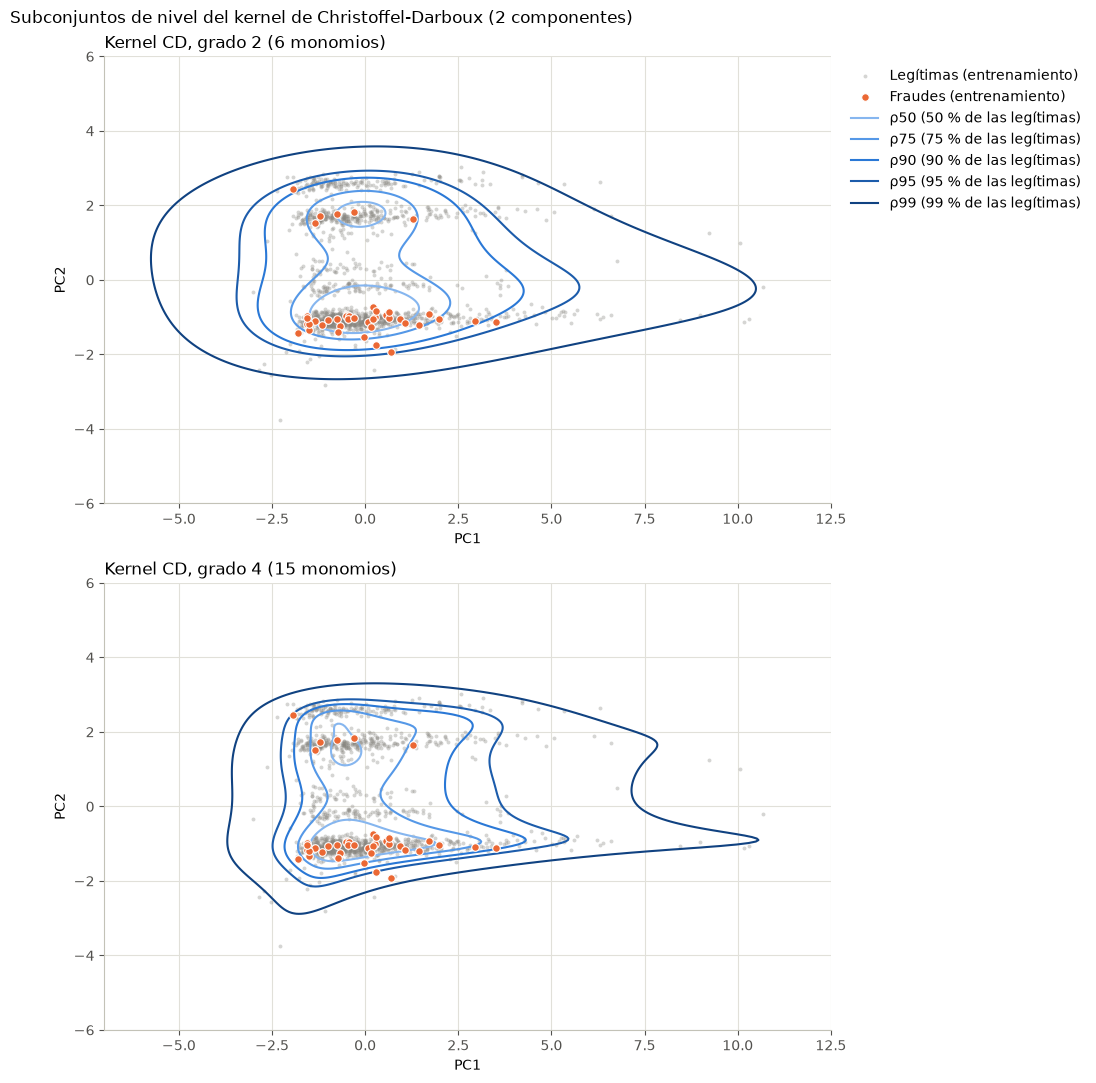

In [232]:
fig, axes = plt.subplots(2, 1, figsize=(11, 11))
for ax, grado in zip(axes, [2, 4]):
    res = resultados_cd[(2, grado)]
    graficar_regiones(ax, puntaje_cd(puntos_malla, res["monomios"], res["M_inv"]), calcular_radios(res["legit"]),
                      f"Kernel CD, grado {grado} ({len(res['monomios'])} monomios)")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Subconjuntos de nivel del kernel de Christoffel-Darboux (2 componentes)", x=0.02, ha="left")
plt.tight_layout()
plt.show()

**Cómo leer la gráfica:**

- **Grado 2 (arriba):** las curvas ya **no son elipses**: se estiran hacia la derecha siguiendo la cola de las legítimas.
- **Grado 4 (abajo):** con más monomios las curvas se pegan todavía más a los datos y rodean las franjas y la cola con formas irregulares.
- **En los dos casos** casi todos los fraudes siguen **dentro** de ρ₉₅ (100 % con grado 2 y 95 % con grado 4, según las tablas de arriba). La frontera es más realista, pero los fraudes viven en las mismas zonas que las legítimas, así que no quedan afuera.

In [233]:
for grado in [2, 4]:
    print(f"\nKernel CD · 2 componentes · grado {grado}")
    display(tabla_zonas(resultados_cd[(2, grado)]))
    display(tabla_confusion(resultados_cd[(2, grado)]))


Kernel CD · 2 componentes · grado 2


,puntaje hasta,legítimas,fraudes,% fraude en la zona
zona,,,,
Seguridad extrema,1.63,21,1,4.55
Seguridad alta,1.87,27,1,3.57
Seguridad baja,3.00,110,3,2.65
Peligro,inf,217,5,2.25


,VN,FP,FN,VP
umbral,,,,
ρ50,177,198,6,4
ρ75,293,82,8,2
ρ90,345,30,10,0
ρ95,359,16,10,0
ρ99,373,2,10,0



Kernel CD · 2 componentes · grado 4


,puntaje hasta,legítimas,fraudes,% fraude en la zona
zona,,,,
Seguridad extrema,2.10,13,0,0.00
Seguridad alta,2.98,64,3,4.48
Seguridad baja,4.48,52,0,0.00
Peligro,inf,246,7,2.77


,VN,FP,FN,VP
umbral,,,,
ρ50,175,200,4,6
ρ75,295,80,10,0
ρ90,343,32,10,0
ρ95,358,17,10,0
ρ99,372,3,10,0


### 3.6 Con 5, 7 y 10 componentes

Mismo método con bases de grado 2 y 4. La última columna es una **señal de sobreajuste**: ρ₉₅ se eligió para que el 95 % de las legítimas de *entrenamiento* quede dentro. Si el modelo aprendió la forma general de los datos, con legítimas *nuevas* (las del test) debería pasar algo parecido, cerca del 95 %.

In [234]:
for k in [5, 7, 10]:
    for grado in [2, 4]:
        resultados_cd[(k, grado)] = correr_cd(k, grado)

filas = []
for (k, grado), res in resultados_cd.items():
    rho95 = radio(res["legit"], 95)
    legitimas_test = res["test"][y_real == 0]
    filas.append({
        "k": k,
        "grado": grado,
        "monomios": len(res["monomios"]),
        "tiempo (ms)": 1000 * res["segundos"],
        "% legítimas de test dentro de ρ95": 100 * np.mean(legitimas_test <= rho95),
    })
pd.DataFrame(filas).set_index(["k", "grado"]).round(1)

monomios  tiempo (ms)  % legítimas de test dentro de ρ95
k  grado                                                          
2  2             6          5.1                               95.7
   4            15          3.6                               95.5
5  2            21          4.9                               95.7
   4           126         11.1                               93.3
7  2            36          3.7                               95.7
   4           330         26.7                               87.5
10 2            66          4.5                               95.2
   4          1001        178.1                               30.9

**Cómo leer la tabla:**

- Con grado 2, y con grado 4 hasta 5 componentes, la última columna está entre 93 % y 96 %: el modelo generaliza bien.
- Con 7 componentes y grado 4 baja a 87.5 %, y con 10 componentes y grado 4 se desploma a **30.9 %**: casi 7 de cada 10 legítimas nuevas quedan **fuera** de la región "normal".
- La razón: con 1,001 monomios y solo 1,494 legítimas, el polinomio **memoriza** las transacciones de entrenamiento en lugar de aprender su forma general. Eso es **sobreajuste**, como un traje tan a la medida que no le queda a nadie más.
- El tiempo también crece con el número de monomios, porque M es una matriz de (monomios × monomios) que hay que invertir.

## 4. Comparación final (para el reporte)

Todos los métodos evaluados en `X_test_pca` con el umbral **ρ₉₅**: una transacción es fraude si queda fuera de la región que contiene al 95 % de las legítimas de entrenamiento. El tiempo incluye entrenar y calcular los puntajes de entrenamiento y de prueba; cambia un poco en cada corrida.

In [235]:
filas = [
    fila_resumen("Mahalanobis", "—", maha_2),
    fila_resumen("Mahalanobis", "—", maha_10),
]
for (k, grado), res in resultados_cd.items():
    filas.append(fila_resumen("Kernel CD", f"grado {grado} ({len(res['monomios'])} monomios)", res))

pd.DataFrame(filas).set_index(["método", "k", "base"]).round(1)

varianza explicada (%)  tiempo (ms)  \
método      k  base                                                           
Mahalanobis 2  —                                          22.0          8.2   
            10 —                                          66.9          4.4   
Kernel CD   2  grado 2 (6 monomios)                       22.0          5.1   
               grado 4 (15 monomios)                      22.0          3.6   
            5  grado 2 (21 monomios)                      44.6          4.9   
               grado 4 (126 monomios)                     44.6         11.1   
            7  grado 2 (36 monomios)                      53.8          3.7   
               grado 4 (330 monomios)                     53.8         26.7   
            10 grado 2 (66 monomios)                      66.9          4.5   
               grado 4 (1001 monomios)                    66.9        178.1   

                                         VN   FP  FN  VP  \
método      k  base                                        
Mahalanobis 2  —                        358   17  10   0   
            10 —                        360   15   9   1   
Kernel CD   2  grado 2 (6 monomios)     359   16  10   0   
               grado 4 (15 monomios)    358   17  10   0   
            5  grado 2 (21 monomios)    359   16  10   0   
               grado 4 (126 monomios)   350   25  10   0   
            7  grado 2 (36 monomios)    359   16   9   1   
               grado 4 (330 monomios)   328   47   7   3   
            10 grado 2 (66 monomios)    357   18   9   1   
               grado 4 (1001 monomios)  116  259   2   8   

                                        % fraudes detectados  % falsas alarmas  
método      k  base                                                             
Mahalanobis 2  —                                         0.0               4.5  
            10 —                                        10.0               4.0  
Kernel CD   2  grado 2 (6 monomios)                      0.0               4.3  
               grado 4 (15 monomios)                     0.0               4.5  
            5  grado 2 (21 monomios)                     0.0               4.3  
               grado 4 (126 monomios)                    0.0               6.7  
            7  grado 2 (36 monomios)                    10.0               4.3  
               grado 4 (330 monomios)                   30.0              12.5  
            10 grado 2 (66 monomios)                    10.0               4.8  
               grado 4 (1001 monomios)                  80.0              69.1

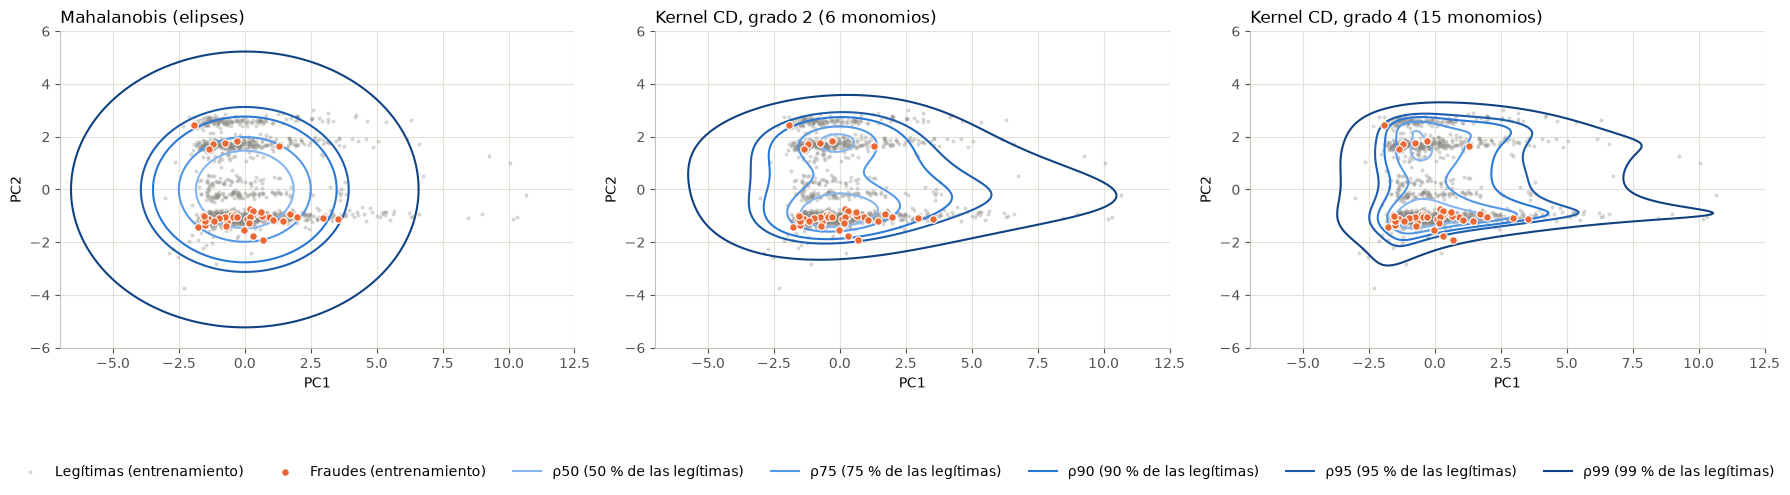

In [236]:
# Las tres gráficas en 2D lado a lado (para el reporte y la presentación)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
graficar_regiones(axes[0], puntaje_mahalanobis(puntos_malla, maha_2["sigma_inv"]),
                  calcular_radios(maha_2["legit"]), "Mahalanobis (elipses)")
for ax, grado in zip(axes[1:], [2, 4]):
    res = resultados_cd[(2, grado)]
    graficar_regiones(ax, puntaje_cd(puntos_malla, res["monomios"], res["M_inv"]),
                      calcular_radios(res["legit"]), f"Kernel CD, grado {grado} ({len(res['monomios'])} monomios)")

fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 5. Resumen para la presentación

**El problema.** Detectar fraudes en 1,921 transacciones de México, de las cuales solo 52 (2.7 %) son fraude.

**La estrategia.** No aprendemos "cómo es un fraude" sino "cómo es una transacción normal". A cada transacción le damos un puntaje de rareza y marcamos como fraude las que superan el umbral ρ₉₅.

**Preparación.** Estandarizamos (para que ninguna columna domine por su escala) y reducimos de 26 columnas a 10 componentes con PCA. Todo se aprende solo con `X_train`; a `X_test` solo se le aplica lo aprendido.

**Método 1 — Mahalanobis.** Puntaje $d_M(x) = \sqrt{x^T \Sigma^{-1} x}$. Las regiones "normales" son elipses.

**Método 2 — Kernel CD.** Puntaje $p_{CD}(x) = \Phi(x)^T M_{reg}^{-1} \Phi(x)$. Es la misma fórmula que Mahalanobis, pero con monomios en lugar de x, por eso las regiones siguen la forma de los datos. Con grado 1 es exactamente Mahalanobis (sección 3.4).

**Resultados (umbral ρ₉₅, 10 fraudes en el test).**

- Casi todas las variantes detectan 0 o 1 de los 10 fraudes, con alrededor de 4 % de falsas alarmas.
- El kernel CD con 7 componentes y grado 4 detecta 3 de 10, pero con 12.5 % de falsas alarmas.
- El kernel CD con 10 componentes y grado 4 "detecta" 8 de 10 solo porque marca como fraude al 69 % de las legítimas. Es el sobreajuste de la sección 3.6, no una mejora real: un detector que acusa a 7 de cada 10 clientes honestos no sirve.

**Por qué no funcionó mejor.**

1. PCA no usa la etiqueta `is_fraud`: conserva las direcciones de mayor varianza, no las que distinguen el fraude. En esas componentes los fraudes **no son atípicos**: están en las mismas zonas que las legítimas, como se ve en las tres gráficas.
2. Una frontera más flexible (kernel CD) describe mejor la forma de los datos, pero no ayuda si los fraudes están dentro de ella.
3. Más grado y más componentes no siempre es mejor: los monomios crecen como $\binom{k+d}{d}$, el tiempo sube y el modelo sobreajusta.
4. Con solo 10 fraudes en el test, cada fraude vale 10 puntos de "% detectados", así que una diferencia de 0 contra 1 fraude puede ser azar.

**Qué se podría mejorar:** elegir variables que sí distingan el fraude en lugar de solo las de mayor varianza, conseguir más ejemplos de fraude, o elegir el umbral comparando el costo de un fraude no detectado con el de una falsa alarma.